## 📓 Notebook 05: Leaderboard Overfitting Simulation

**Skills practiced:** Three-way data splits, deliberate leaderboard probing, checkpointed scoring, multi-line plots.

**Goal:** Tune against a fake public split, check a hidden private split only at set checkpoints, and plot the widening gap against a properly cross-validated model.

In [39]:

import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FormatStrFormatter
import optuna
import xgboost as xgb
from sklearn.model_selection import train_test_split
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.metrics import roc_auc_score

In [2]:
x=pd.read_csv('../data/processed/x.csv')
y=pd.read_csv('../data/processed/y.csv').squeeze()
RANDOM_STATE = 42

In [4]:
X_tmp, x_true_private, y_tmp, y_true_private = train_test_split(x, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
x_train, x_fake_public, y_train, y_fake_public = train_test_split(X_tmp, y_tmp, test_size=0.25, stratify=y_tmp, random_state=RANDOM_STATE)
print(len(x_train), len(x_fake_public), len(x_true_private))

4225 1409 1409


In [ ]:
def objective(trial):
    model = xgb.XGBClassifier(
        max_depth=trial.suggest_int("max_depth", 3, 15),
        learning_rate=trial.suggest_float("learning_rate", 0.005, 0.4, log=True),
        n_estimators=trial.suggest_int("n_estimators", 50, 500),
        random_state=RANDOM_STATE,
    )
    model.fit(x_train, y_train)
    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
    return cross_val_score(model, x_fake_public, y_fake_public, cv=cv, scoring="roc_auc").mean()

study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE))
study.optimize(objective, n_trials=50)

print("Best hyperparameters found: \n", study.best_params)
print("Best AUC score: ", study.best_value)

[I 2026-11-19 00:48:00,439] A new study created in memory with name: no-name-d12514cc-9a78-4c58-b1fa-f1f20a08db1f
[I 2026-11-19 00:48:05,446] Trial 0 finished with value: 0.7999167863515689 and parameters: {'max_depth': 7, 'learning_rate': 0.3223033958565721, 'n_estimators': 380}. Best is trial 0 with value: 0.7999167863515689.
[I 2026-11-19 00:48:08,431] Trial 1 finished with value: 0.819633720677199 and parameters: {'max_depth': 10, 'learning_rate': 0.009905753504069, 'n_estimators': 120}. Best is trial 1 with value: 0.819633720677199.
[I 2026-11-19 00:48:11,680] Trial 2 finished with value: 0.7974374374374376 and parameters: {'max_depth': 3, 'learning_rate': 0.22252620134763365, 'n_estimators': 321}. Best is trial 1 with value: 0.819633720677199.
[I 2026-11-19 00:48:21,016] Trial 3 finished with value: 0.8202608695652174 and parameters: {'max_depth': 12, 'learning_rate': 0.005471975564178365, 'n_estimators': 487}. Best is trial 3 with value: 0.8202608695652174.
[I 2026-11-19 00:48:2

Best hyperparameters found: 
 {'max_depth': 3, 'learning_rate': 0.007132947773984496, 'n_estimators': 464}
Best AUC score:  0.8401303042172608


In [56]:
for n in range(10, len(study.trials) + 1, 10):
    best = max(study.trials[:n], key=lambda t: t.value)
    print(n, round(best.value, 4), best.params)
    

10 0.8353 {'max_depth': 4, 'learning_rate': 0.017986537177907398, 'n_estimators': 215}
20 0.8401 {'max_depth': 3, 'learning_rate': 0.007132947773984496, 'n_estimators': 464}
30 0.8401 {'max_depth': 3, 'learning_rate': 0.007132947773984496, 'n_estimators': 464}
40 0.8401 {'max_depth': 3, 'learning_rate': 0.007132947773984496, 'n_estimators': 464}
50 0.8401 {'max_depth': 3, 'learning_rate': 0.007132947773984496, 'n_estimators': 464}


In [68]:
m=xgb.XGBClassifier(
        max_depth=3,
        learning_rate=0.0095,
        n_estimators=500,
        random_state=RANDOM_STATE,
        subsample=0.8, 
        colsample_bytree=0.8,
    )
m.fit(x_train, y_train)

scores = cross_val_score(m, x_fake_public, y_fake_public, cv=5, scoring="roc_auc")
print(f"'fake public' data validation score {scores.mean():.4f}")

scores = cross_val_score(m, x_true_private, y_true_private, cv=5, scoring="roc_auc")
print(f"'true private' data validation score {scores.mean():.4f}")

'fake public' data validation score 0.8402
'true private' data validation score 0.8369


In [ ]:
public = pd.Series([t.value for t in study.trials[:50]])

fixed = dict(random_state=RANDOM_STATE)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

rows = []
for n in [10, 20, 30,40,50]:
    best_i = public.iloc[:n].idxmax()
    params = {**fixed, **study.trials[best_i].params}

    m = xgb.XGBClassifier(**params)
    m.fit(x_train, y_train)

    rows.append({
        "checkpoint": n,
        "cv": cross_val_score(m, x_train, y_train, cv=cv, scoring="roc_auc").mean(),
        "public": roc_auc_score(y_fake_public, m.predict_proba(x_fake_public)[:, 1]),
        "private": roc_auc_score(y_true_private, m.predict_proba(x_true_private)[:, 1]),
    })

results = pd.DataFrame(rows)
print(results)

   checkpoint        cv    public   private
0          10  0.847590  0.838795  0.845799
1          20  0.848063  0.839349  0.843666
2          30  0.848063  0.839349  0.843666
3          40  0.848063  0.839349  0.843666
4          50  0.848063  0.839349  0.843666


In [64]:
best_cv_model = xgb.XGBClassifier(**{**fixed, **study.best_params})
best_cv_model.fit(x_train, y_train)
ref = roc_auc_score(y_true_private, best_cv_model.predict_proba(x_true_private)[:, 1])
print(ref)

0.8436655558138934


In [66]:
def spread(ys, min_gap):
    order = sorted(range(len(ys)), key=lambda i: ys[i])
    out = list(ys)
    for k in range(1, len(order)):
        lower, upper = order[k - 1], order[k]
        if out[upper] - out[lower] < min_gap:
            out[upper] = out[lower] + min_gap
    return out

def make_headline(results, ref):
    pub, priv = results["public"], results["private"]
    moved = pub.max() - pub.min()
    gap = pub.iloc[-1] - priv.iloc[-1]
    if moved < 0.002:
        return ("More tuning did not change the scores",
                "The best settings were found early; later trials added nothing.")
    if gap > 0.003:
        return (f"Tuning on the public score inflated it by {gap:.3f} AUC",
                "The public score kept improving, but unseen (private) performance did not follow.")
    return ("Public and private scores stayed close",
            "Tuning against the public score did not create a misleading gain.")

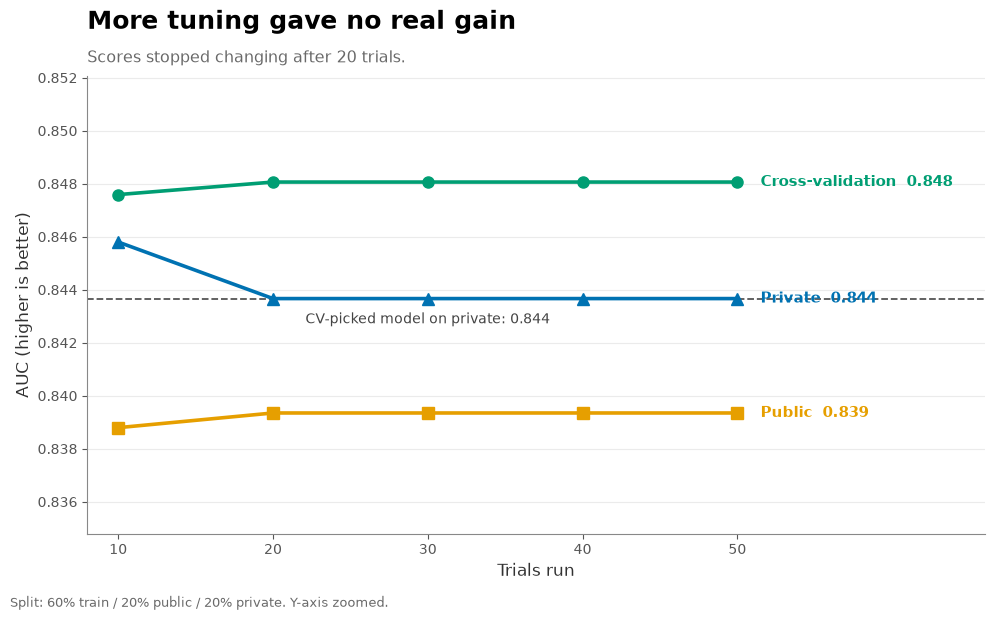

In [73]:

x = results["checkpoint"]
cols = ["cv", "public", "private"]
style = {
    "cv":      ("#009E73", "o", "Cross-validation"),
    "public":  ("#E69F00", "s", "Public"),
    "private": ("#0072B2", "^", "Private"),
}

lo = min(results[cols].min().min(), ref) - 0.004
hi = max(results[cols].max().max(), ref) + 0.004
span = hi - lo

fig, ax = plt.subplots(figsize=(10, 6))

# benchmark line + short label placed below the line, mid-chart
ax.axhline(ref, color="#555555", linestyle="--", linewidth=1.3, zorder=1)
ax.text(x.iloc[2], ref - span * 0.03, f"CV-picked model on private: {ref:.3f}",
        ha="center", va="top", fontsize=10, color="#444444",
        bbox=dict(facecolor="white", edgecolor="none", pad=1.5))

# the three lines
for c in cols:
    color, marker, _ = style[c]
    ax.plot(x, results[c], color=color, marker=marker,
            markersize=8, linewidth=2.6, zorder=3)

# end-of-line labels, pushed apart so they never overlap
ends = [results[c].iloc[-1] for c in cols]
label_y = spread(ends, span * 0.07)
for c, y_end, y_lab in zip(cols, ends, label_y):
    color, _, name = style[c]
    ax.text(x.iloc[-1] + 1.5, y_lab, f"{name}  {y_end:.3f}",
            color=color, fontsize=11, fontweight="bold", va="center")

# axes
ax.set_ylim(lo, hi)
ax.set_xlim(x.iloc[0] - 2, x.iloc[-1] + 16)
ax.set_xticks(x)
ax.yaxis.set_major_formatter(FormatStrFormatter("%.3f"))
ax.set_xlabel("Trials run", fontsize=12)
ax.set_ylabel("AUC (higher is better)", fontsize=12)

# short title and subtitle
ax.set_title("More tuning gave no real gain", loc="left",
             fontsize=18, fontweight="bold", pad=34)
ax.text(0, 1.03, "Scores stopped changing after 20 trials.",
        transform=ax.transAxes, fontsize=11.5, color="dimgray")

# clean look
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", alpha=0.25)
ax.set_axisbelow(True)

fig.text(0.01, -0.02, "Split: 60% train / 20% public / 20% private. Y-axis zoomed.",
         fontsize=9.5, color="dimgray")

fig.tight_layout()
fig.savefig("../outputs/figures/leaderboard_probing.png", dpi=200, bbox_inches="tight")
plt.show()